In [1]:
import os
from dotenv import load_dotenv
load_dotenv

<function dotenv.main.load_dotenv(dotenv_path: Union[str, ForwardRef('os.PathLike[str]'), NoneType] = None, stream: Optional[IO[str]] = None, verbose: bool = False, override: bool = False, interpolate: bool = True, encoding: Optional[str] = 'utf-8') -> bool>

In [2]:
from langchain.chat_models import init_chat_model
llm=init_chat_model('google_genai:gemini-3.5-flash-lite')
llm

ChatGoogleGenerativeAI(metadata={'lc_versions': {'langchain-core': '1.7.3', 'langchain': '1.4.7', 'langchain-google-genai': '4.4.2'}}, profile={'name': 'Gemini 3.5 Flash Lite', 'release_date': '2026-07-21', 'last_updated': '2026-07-21', 'open_weights': False, 'max_input_tokens': 1048576, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': True, 'pdf_inputs': True, 'video_inputs': True, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'image_tool_message': True, 'tool_choice': True, 'reasoning_effort_levels': ['minimal', 'low', 'medium', 'high'], 'reasoning_effort_default': 'minimal'}, google_api_key=SecretStr('**********'), model='gemini-3.5-flash-lite', temperature=None, client=<google.genai.client.Client object at 0x000001680EA3B990>, default_metadata=(), model_kwar

In [12]:
from langchain_tavily import TavilySearch
from langchain.tools import tool
from langgraph.types import interrupt,Command

search_tool=TavilySearch(max_results=2)

@tool
def HumanAssistance(query:str)->str:
  """
  Assistance from Human
  """
  human_response=interrupt({'query':query})
  return human_response['data']

tools=[search_tool,HumanAssistance]

llm_with_tool=llm.bind_tools(tools)


In [13]:
## Now create the graph
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Annotated
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode , tools_condition

class State(TypedDict):
  messages:Annotated[list,add_messages]

graph_builder=StateGraph(State)

def chatBot(state:State):
  return {
    'messages':[llm_with_tool.invoke(state['messages'])]
}

graph_builder.add_node('chatbot',chatBot)
tool_node=ToolNode(tools=tools)
graph_builder.add_node('tools',tool_node)

#edges
graph_builder.add_edge(START,'chatbot')
graph_builder.add_conditional_edges('chatbot',tools_condition)

graph_builder.add_edge('tools','chatbot')



In [14]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()
graph=graph_builder.compile(checkpointer=memory)

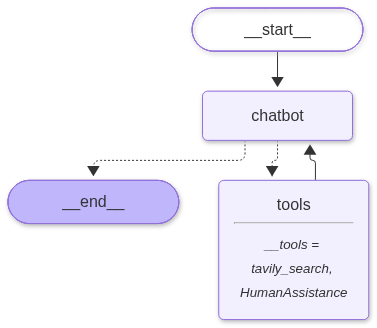

In [15]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    # This requires some extra dependencies and is optional
    pass

In [16]:
config={
  'configurable':{'thread_id':'1'}
}

user_input = "I need some expert guidance and assistance for building an AI agent. Could you request assistance for me?"
events=graph.stream({
  'messages':user_input
},config,stream_mode="values")

for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================ Human Message =================================

I need some expert guidance and assistance for building an AI agent. Could you request assistance for me?
================================== Ai Message ==================================

[]
Tool Calls:
  HumanAssistance (call_15724308243662376759)
 Call ID: call_15724308243662376759
  Args:
    query: User needs expert guidance and assistance for building an AI agent.
================================== Ai Message ==================================

[]
Tool Calls:
  HumanAssistance (call_15724308243662376759)
 Call ID: call_15724308243662376759
  Args:
    query: User needs expert guidance and assistance for building an AI agent.


In [17]:
human_response = (
    "We, the experts are here to help! We'd recommend you check out LangGraph to build your agent."
    " It's much more reliable and extensible than simple autonomous agents."
)

human_command=Command(resume={'data':human_response})
events=graph.stream(human_command,config,stream_mode="values")

for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================== Ai Message ==================================

[]
Tool Calls:
  HumanAssistance (call_15724308243662376759)
 Call ID: call_15724308243662376759
  Args:
    query: User needs expert guidance and assistance for building an AI agent.
================================= Tool Message =================================
Name: HumanAssistance

We, the experts are here to help! We'd recommend you check out LangGraph to build your agent. It's much more reliable and extensible than simple autonomous agents.
================================== Ai Message ==================================

[{'type': 'text', 'text': 'The expert team has chimed in! They recommend checking out **LangGraph** to build your AI agent, noting that it provides much better reliability and extensibility compared to simple autonomous agents.\n\nTo help you get started on the right foot, could you share a bit more about what you want your AI agent to do? For example:\n1. What is the core use case